# Pronóstico de demanda y reducción de merma en una cadena gastronómica

**Pregunta de negocio:** ¿cuánto se puede reducir el desperdicio de productos frescos (medialunas, tostados, wraps, limonadas) si la producción diaria se decide con un modelo predictivo en lugar de la regla manual de *"lo que vendimos los últimos martes, más un 20% por las dudas"*?

**Contexto:** cadena de 4 sucursales tipo café/deli en La Plata. Los datos son **sintéticos**, generados con patrones observados en la operación real del rubro (estacionalidad, promociones, feriados, vacaciones de enero), porque los datos reales de ventas son confidenciales.

**Contenido**
1. Exploración de los datos
2. Patrones de demanda: día de la semana, estacionalidad y promociones
3. Modelo de pronóstico a 1 día y comparación con la regla manual
4. Simulación de producción: merma vs nivel de servicio
5. Conclusiones y recomendaciones

In [1]:
import sys
sys.path.append("..")  # para importar el paquete src/ desde notebooks/

import pandas as pd
from src import pipeline, graficos as g, modelo

pd.set_option("display.float_format", "{:,.2f}".format)
r = pipeline.ejecutar()
ventas = r.ventas
print(f"{len(ventas):,} registros | {ventas['fecha'].min():%d/%m/%Y} a {ventas['fecha'].max():%d/%m/%Y}")
print(f"{ventas['sucursal'].nunique()} sucursales, {ventas['producto'].nunique()} productos")

35,088 registros | 01/01/2023 a 31/12/2024
4 sucursales, 12 productos


## 1. Exploración de los datos

Cada fila es la venta diaria de un producto en una sucursal.

In [2]:
ventas.head()

,fecha,sucursal,producto,categoria,unidades,precio_unitario,costo_unitario,en_promocion,es_feriado,ingreso
0,2023-01-01,Centro,Café con leche,Bebida caliente,70,3200,900,0,1,224000
1,2023-01-02,Centro,Café con leche,Bebida caliente,43,3200,900,0,0,137600
2,2023-01-03,Centro,Café con leche,Bebida caliente,71,3200,900,0,0,227200
3,2023-01-04,Centro,Café con leche,Bebida caliente,85,3200,900,0,0,272000
4,2023-01-05,Centro,Café con leche,Bebida caliente,86,3200,900,0,0,275200


In [3]:
resumen_suc = (ventas.groupby("sucursal")
               .agg(unidades=("unidades", "sum"), ingresos=("ingreso", "sum"))
               .sort_values("ingresos", ascending=False))
resumen_suc["participacion_%"] = 100 * resumen_suc["ingresos"] / resumen_suc["ingresos"].sum()
resumen_suc

,unidades,ingresos,participacion_%
sucursal,,,
Centro,513620,1357196515,33.65
City Bell,394445,1044114160,25.89
Gonnet,335784,889711880,22.06
Los Hornos,278845,742283415,18.40


In [4]:
# Control de calidad básico: nulos, negativos y duplicados
print("Nulos por columna:", ventas.isna().sum().sum())
print("Unidades negativas:", (ventas["unidades"] < 0).sum())
print("Duplicados fecha+sucursal+producto:", ventas.duplicated(["fecha", "sucursal", "producto"]).sum())

Nulos por columna: 0
Unidades negativas: 0
Duplicados fecha+sucursal+producto: 0


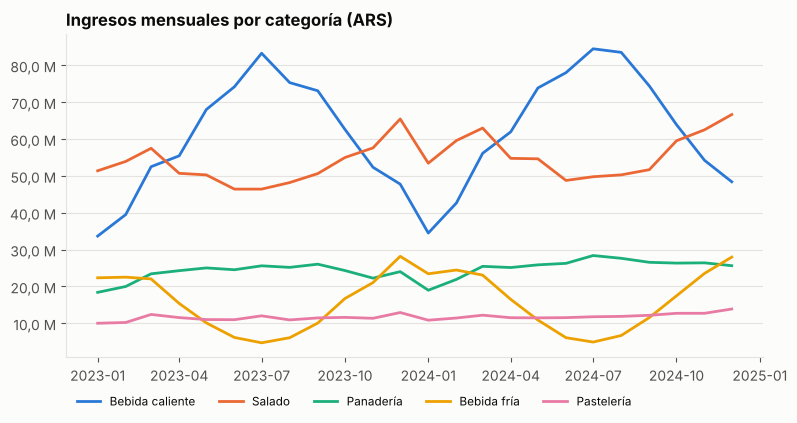

In [5]:
g.ingresos_mensuales_por_categoria(ventas)

Se ven dos patrones opuestos: las **bebidas calientes** tienen su pico en invierno (junio–agosto) y las **bebidas frías** en verano. Enero muestra una baja general por vacaciones (ciudad universitaria). Hay una tendencia de crecimiento leve entre 2023 y 2024.

## 2. Patrones de demanda

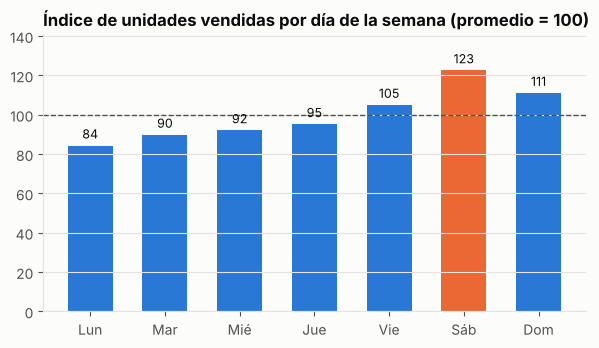

In [6]:
g.efecto_dia_semana(ventas)

El **sábado vende 23% más que el promedio** y el lunes 16% menos. Una regla de producción plana para toda la semana genera merma los lunes y faltantes los sábados.

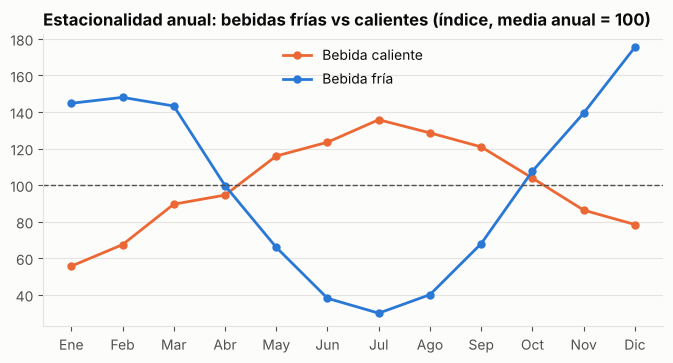

In [7]:
g.estacionalidad_bebidas(ventas)

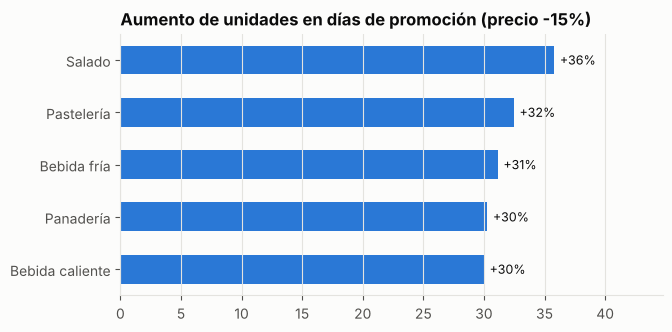

In [8]:
g.efecto_promociones(ventas)

Las promociones (15% de descuento) aumentan las unidades en un **30–36%**. Como la regla manual mira el pasado, no "sabe" que mañana hay promoción y produce de menos; el modelo recibe el calendario de promociones como variable.

## 3. Modelo de pronóstico

- **Horizonte:** 1 día (la producción se decide la tarde anterior).
- **Variables:** día de la semana, mes, posición en el año (seno/coseno), promoción, feriado, ventas de ayer, de hace 7 y 14 días, y medias móviles de 7 y 28 días.
- **Algoritmo:** Gradient Boosting (`HistGradientBoostingRegressor`) con pérdida de Poisson, adecuada para conteos de unidades.
- **Validación temporal:** entrena con datos hasta agosto 2024 y se evalúa en **septiembre–diciembre 2024**, datos que el modelo nunca vio. No se mezclan fechas futuras en el entrenamiento.

In [9]:
r.metricas

,MAE,WAPE_%,sesgo_%
Promedio 4 mismos días (manual),14.43,31.31,0.61
Mismo día semana pasada,18.11,39.31,0.03
Gradient Boosting (modelo),12.65,27.46,-2.08


**WAPE** = error absoluto total / unidades vendidas totales. Es la métrica estándar en retail porque pondera por volumen.
El modelo reduce el error frente a la regla manual y también frente a "copiar la semana pasada". El sesgo levemente negativo (subestima ~2%) se compensa con el stock de seguridad en la sección siguiente.

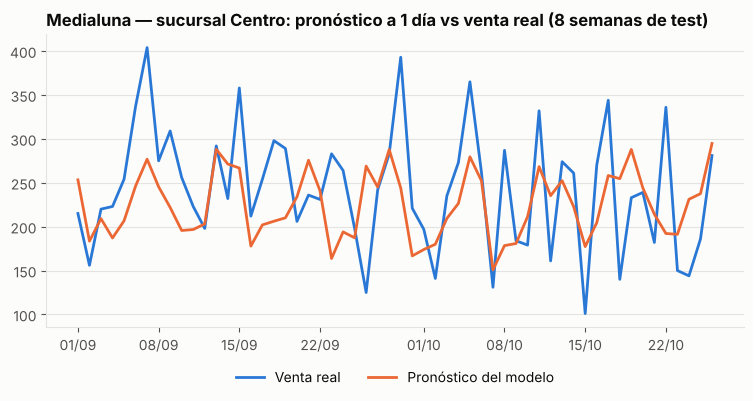

In [10]:
g.pronostico_vs_real(r.test)

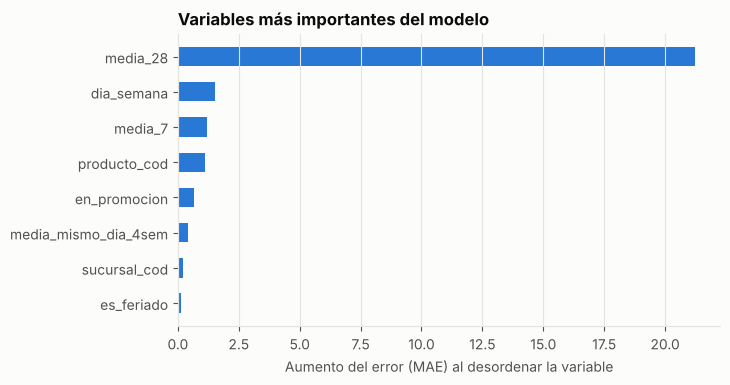

In [11]:
g.importancia_variables(r.modelo, r.test, modelo.FEATURES)

## 4. Simulación de producción: merma vs nivel de servicio

Un mejor pronóstico solo vale si se traduce en plata. Se simula la producción diaria de los **6 productos con vida útil de 1 día** durante el período de test:

- Lo que sobra al cierre se descarta → **merma**.
- Lo que falta es venta perdida → baja el **nivel de servicio** (% de la demanda atendida).

Producir más reduce los faltantes pero aumenta la merma. Por eso se compara cada política **al mismo nivel de servicio**: si no, cualquiera "gana" produciendo menos.

- **Manual:** promedio de los últimos 4 mismos días × (1 + colchón), con colchones de 0% a 60%.
- **Modelo:** pronóstico + z × desvío esperado del error (calibrado en julio–agosto, antes del test).

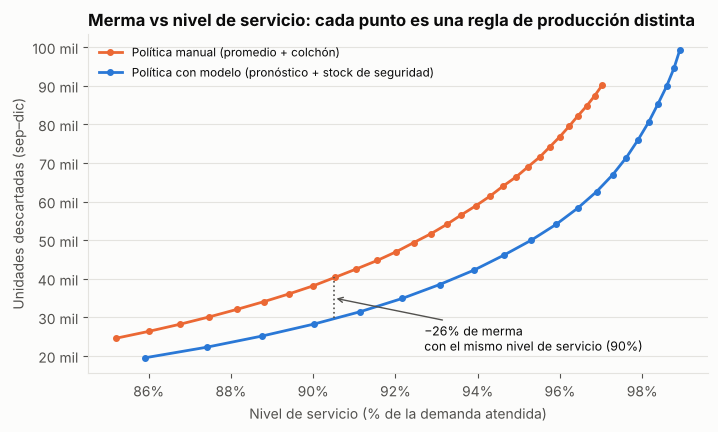

In [12]:
g.frontera_merma(r.curva_manual, r.curva_modelo, r.resumen)

In [13]:
for k, v in r.resumen.items():
    print(f"{k:28s} {v}")

periodo_test                 2024-09-01 a 2024-12-31
productos_simulados          ['Limonada', 'Té helado', 'Medialuna', 'Tostado jamón y queso', 'Wrap de pollo', 'Ensalada bowl']
nivel_servicio_%             90.5
merma_manual_unidades        40323
merma_modelo_unidades        29691
reduccion_merma_%            26.4
ahorro_costo_mensual_ARS     1474101
mejora_WAPE_pp               3.8


## 5. Conclusiones

1. Con el **mismo nivel de servicio** que la regla manual del 20% (≈90%), la política basada en el modelo **reduce la merma de productos frescos en ~26%**.
2. La curva azul está por debajo de la naranja en todo el rango: no es un ajuste puntual, el modelo es mejor para cualquier nivel de servicio que elija el negocio.
3. La mayor parte de la ganancia viene de anticipar **promociones**, **días de la semana** y **cambios de estación**, que la regla manual detecta tarde.

**Recomendaciones operativas**
- Publicar cada tarde una planilla de producción sugerida por sucursal y producto (pronóstico + stock de seguridad).
- Definir el nivel de servicio objetivo por producto: más alto para productos ancla (medialunas, café) y más bajo para productos de baja rotación.
- Registrar la hora del último faltante del día para medir la demanda real (hoy, lo que no se vendió por falta de stock no queda registrado).

**Limitaciones:** datos sintéticos; la demanda se asume no censurada; no se modelan donaciones ni reaprovechamiento de sobrantes.